# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
import pandas as pd

url = "/content/sample_data/Lab_11_QnA_Dataset.csv"

df = pd.read_csv(url)

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())

display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

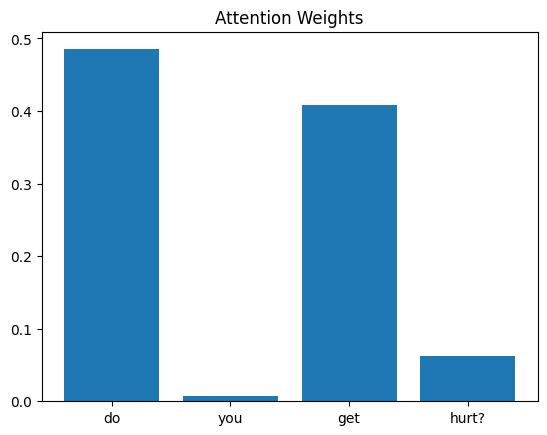

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

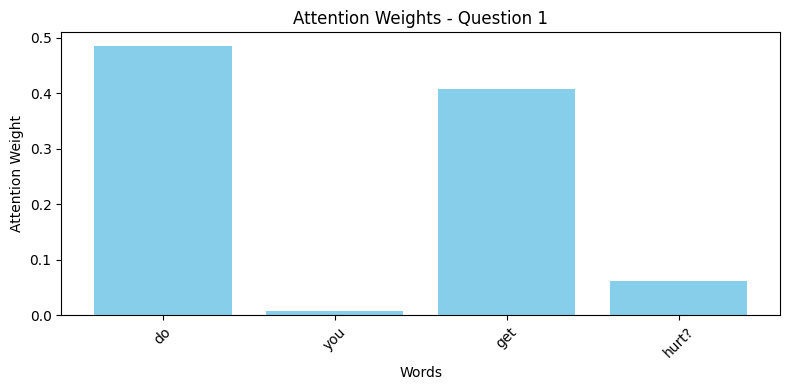

Question: do you get hurt?
Word with highest attention: do
Highest attention weight: 0.4851
--------------------------------------------------


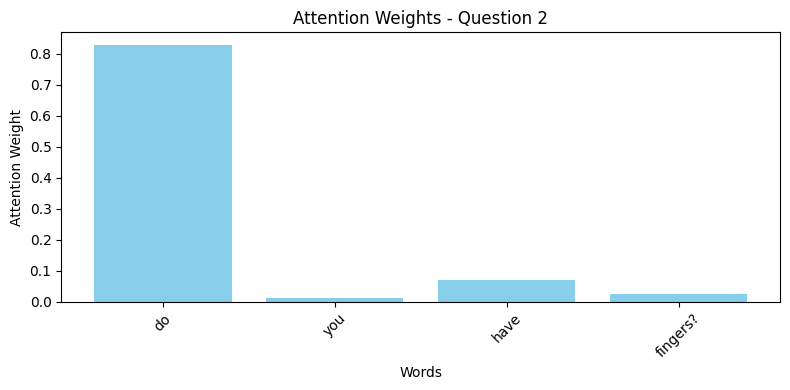

Question: do you have fingers?
Word with highest attention: do
Highest attention weight: 0.827
--------------------------------------------------


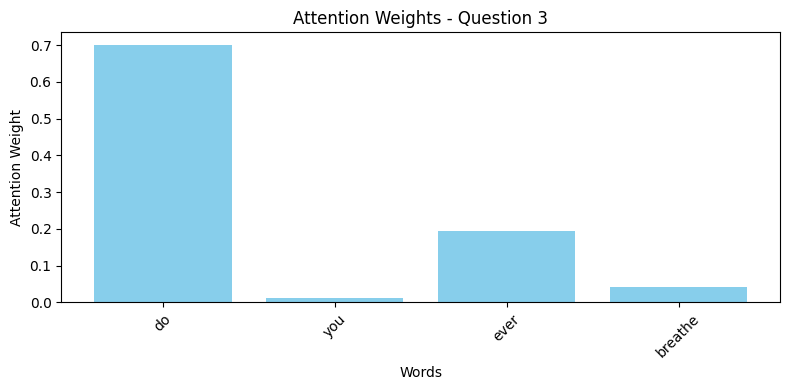

Question: do you ever breathe
Word with highest attention: do
Highest attention weight: 0.6996
--------------------------------------------------


In [7]:

# Step 6 - Visualize attention weights for three questions

# Select three questions
for i in range(3):

    question = df["question"].iloc[i]
    words = question.split()

    # Get model prediction and attention weights
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    # Get attention weights for actual words
    attention = weights[0, :len(words)].tolist()

    # Find the word with the highest attention
    max_index = attention.index(max(attention))
    important_word = words[max_index]

    # Plot attention weights
    plt.figure(figsize=(8, 4))
    plt.bar(words, attention, color="skyblue")
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print("Question:", question)
    print("Word with highest attention:", important_word)
    print("Highest attention weight:", round(max(attention), 4))
    print("-" * 50)


**Yes, the words with the highest attention weights generally appear important for understanding the question. The attention mechanism helps the model focus on meaningful words that provide information about the question's meaning.
For example, words such as "what", "where", "when", or important keywords related to the question may receive higher attention weights.
However, the model does not always focus on the most meaningful word. Sometimes it may assign higher weights to other words because of what it learned during training.
This shows that attention helps the model identify relevant information when predicting an answer.**

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

In [8]:

# Display questions to find two with similar meanings

for i in range(min(20, len(df))):
    print(i, ":", df["question"].iloc[i])


0 : do you get hurt?
1 : do you have fingers?
2 : do you ever breathe
3 : do you masticate?
4 : can you throw up?
5 : do you get tired?
6 : can you crawl?
7 : can you cry?
8 : do you dream
9 : do you ever pee?
10 : do you ever get hurt?
11 : can you breathe
12 : can you masticate?
13 : can you burp?
14 : are you old?
15 : are we the same age?
16 : how long have you been alive?
17 : are you a teenager?
18 : what's your birthday?
19 : which of us is younger?


Question: do you get hurt?
Predicted answer ID: 0
Highest attention word: do


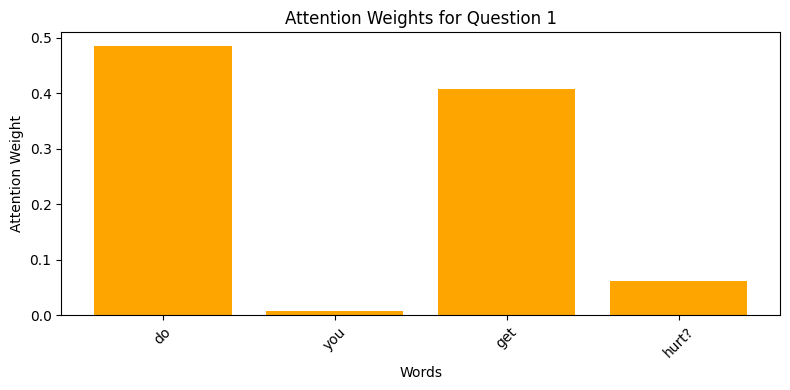

Question: do you have fingers?
Predicted answer ID: 0
Highest attention word: do


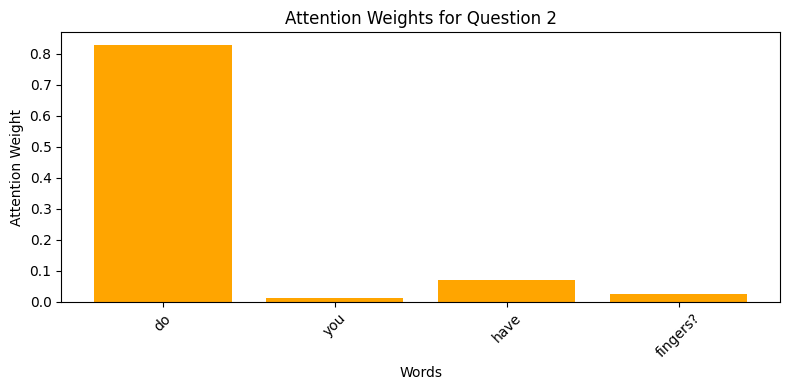

In [9]:

# Step 7 - Compare attention for two similar questions

# Select two question indexes from your dataset
idx1 = 0
idx2 = 1

selected_indices = [idx1, idx2]

for idx in selected_indices:

    question = df["question"].iloc[idx]
    words = question.split()

    # Get prediction and attention weights
    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    attention = weights[0, :len(words)].tolist()

    # Find the word with highest attention
    max_index = attention.index(max(attention))

    print("Question:", question)
    print("Predicted answer ID:", prediction.argmax(dim=1).item())
    print("Highest attention word:", words[max_index])

    # Plot attention
    plt.figure(figsize=(8, 4))
    plt.bar(words, attention, color="orange")
    plt.title(f"Attention Weights for Question {idx+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


**The model may focus on similar words or different words when processing questions with similar meanings.
For example, two questions may use different wording but contain keywords with similar meanings. The attention mechanism can assign higher weights to these important words.
If the model focuses on similar words, it suggests that attention can recognize important information shared between questions.
If it focuses on different words, it suggests that attention considers the context and wording of each individual question.
This shows that attention allows the neural network to assign different importance to words depending on the input question.**